# EKF Hard Scenario Stress Tests

Analysis of the quaternion drone-physics EKF under four demanding racing scenarios:
**sprint**, **slalom**, **pitch_dive**, **dropout**.

Data is recorded with `hard_scenario_record.launch.py` using `hard_test_ekf.yaml`.
Key difference from the easy scenarios: **VIO orientation is disabled** — the EKF
must reconstruct heading purely from angular-rate integration and the drone physics
prediction model. Vision at 5 Hz is the sole source of absolute orientation.

Each test directory contains:
- `scenario_data.csv` — EKF odometry (pose + twist + covariance)
- `accel_data.csv`    — EKF accel output (linear + angular accel + covariance)

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
import yaml

## Utility functions

In [2]:
# Always use scientific notation on all axes
plt.rcParams.update({
    "axes.formatter.use_mathtext": True,
    "axes.formatter.limits": (0, 0),
})


def add_rpy_from_quat(
    input_df: pd.DataFrame,
    xq_col: str = "xq",
    yq_col: str = "yq",
    zq_col: str = "zq",
    w_col: str = "w",
) -> pd.DataFrame:
    """Add roll, pitch, yaw (degrees) columns derived from quaternion columns.

    Uses the standard ZYX (yaw-pitch-roll) Euler decomposition.

    Args:
        input_df: DataFrame with quaternion columns.
        xq_col, yq_col, zq_col, w_col: Column names for the quaternion components.

    Returns:
        Copy of input_df with added columns 'roll_deg', 'pitch_deg', 'yaw_deg'.
    """
    df = input_df.copy()
    x = df[xq_col].to_numpy()
    y = df[yq_col].to_numpy()
    z = df[zq_col].to_numpy()
    w = df[w_col].to_numpy()

    # Roll
    t0 = 2.0 * (w * x + y * z)
    t1 = 1.0 - 2.0 * (x * x + y * y)
    roll = np.arctan2(t0, t1)

    # Pitch
    t2 = np.clip(2.0 * (w * y - z * x), -1.0, 1.0)
    pitch = np.arcsin(t2)

    # Yaw
    t3 = 2.0 * (w * z + x * y)
    t4 = 1.0 - 2.0 * (y * y + z * z)
    yaw = np.arctan2(t3, t4)

    df["roll_deg"]  = np.rad2deg(roll)
    df["pitch_deg"] = np.rad2deg(pitch)
    df["yaw_deg"]   = np.rad2deg(yaw)
    return df


def find_t_rel(df: pd.DataFrame) -> pd.Series:
    """Return relative time (seconds) starting from zero."""
    t_abs = df["t_sec"] + df["t_nsec"] * 1e-9
    return t_abs - t_abs.iloc[0]


def trim_to_duration(df: pd.DataFrame, max_sec: float) -> pd.DataFrame:
    """Drop rows beyond max_sec from the start of the recording."""
    return df[find_t_rel(df) <= max_sec].reset_index(drop=True)


def subtract_velocity_trend(df: pd.DataFrame, velocity: float) -> pd.DataFrame:
    """Remove a constant-velocity linear trend from the x column.

    Adds a new column 'x_detrended' to the dataframe.
    """
    t_rel = find_t_rel(df)
    df["x_detrended"] = df["x"] - velocity * t_rel
    return df

In [3]:
def plot_heatmaps_xyz(input_df: pd.DataFrame) -> None:
    """Hex-bin heatmaps of the XY, YZ, and XZ position pairs."""
    sns.set_theme(style="darkgrid", context="notebook", palette="rocket")
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)
    pairs = [("x", "y"), ("y", "z"), ("x", "z")]
    mappable = None
    for ax, (a, b) in zip(axes, pairs):
        mappable = ax.hexbin(input_df[a], input_df[b], gridsize=40, cmap="magma", mincnt=1)
        ax.set_xlabel(f"{a} [m]")
        ax.set_ylabel(f"{b} [m]")
        ax.set_title(f"Heatmap: {a.upper()} vs {b.upper()}", weight="bold")
        ax.set_aspect("equal", "box")
    fig.colorbar(mappable, ax=axes, orientation="vertical", label="Count")
    plt.show()


def plot_time_series_scatter_xyz(input_df: pd.DataFrame) -> None:
    """Time-series scatter of x, y, z position."""
    sns.set_theme(style="darkgrid", context="notebook", palette="rocket")
    t_rel = find_t_rel(input_df)
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)
    for ax, coord in zip(axes, ["x", "y", "z"]):
        ax.scatter(t_rel, input_df[coord], s=12, color="tab:blue", alpha=0.85, edgecolors="none")
        ax.set_xlabel("t [s]")
        ax.set_ylabel(f"{coord} [m]")
        ax.set_title(f"{coord.upper()} vs Time", weight="bold")
    plt.show()


def plot_time_series_scatter_accel(input_df: pd.DataFrame) -> None:
    """Time-series scatter of ax, ay, az linear acceleration estimates."""
    sns.set_theme(style="darkgrid", context="notebook", palette="rocket")
    t_rel = find_t_rel(input_df)
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)
    for ax, coord in zip(axes, ["ax", "ay", "az"]):
        ax.scatter(t_rel, input_df[coord], s=12, color="tab:orange", alpha=0.85, edgecolors="none")
        ax.set_xlabel("t [s]")
        ax.set_ylabel(f"{coord} [m/s\u00b2]")
        ax.set_title(f"{coord.upper()} vs Time", weight="bold")
    plt.show()


def plot_time_series_covariance_rpy(input_df: pd.DataFrame) -> None:
    """Time-series of EKF orientation covariance (1σ) for roll, pitch, yaw."""
    sns.set_theme(style="darkgrid", context="notebook", palette="rocket")
    t_rel = find_t_rel(input_df)
    rad2deg = 180.0 / np.pi
    sigmas = [
        np.sqrt(input_df["pose_cov_21"].to_numpy()) * rad2deg,
        np.sqrt(input_df["pose_cov_28"].to_numpy()) * rad2deg,
        np.sqrt(input_df["pose_cov_35"].to_numpy()) * rad2deg,
    ]
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)
    for ax, sigma, label in zip(axes, sigmas, ["roll", "pitch", "yaw"]):
        ax.scatter(t_rel, sigma, s=12, alpha=0.85, edgecolors="none")
        ax.set_xlabel("t [s]")
        ax.set_ylabel("1\u03c3 uncertainty [deg]")
        ax.set_title(f"{label.upper()} covariance vs Time", weight="bold")
    plt.show()


def plot_position_error_boxplot(input_df: pd.DataFrame, ref: dict | None = None) -> None:
    """Boxplots of absolute position and orientation errors vs a reference.

    Args:
        input_df: DataFrame with columns x, y, z, roll_deg, pitch_deg, yaw_deg.
        ref: Optional dict with keys x, y, z, roll, pitch, yaw for the ground-truth
             reference values. Defaults to zero for all axes.
    """
    sns.set_theme(style="darkgrid", context="notebook", palette="rocket")
    if ref is None:
        ref = {k: 0.0 for k in ("x", "y", "z", "roll", "pitch", "yaw")}

    pos_data   = [np.abs(input_df[c].to_numpy() - ref[c]) for c in ("x", "y", "z")]
    ori_data   = [np.abs(input_df[f"{c}_deg"].to_numpy() - ref[c]) for c in ("roll", "pitch", "yaw")]

    fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), constrained_layout=True)
    axes[0].boxplot(pos_data, notch=True, labels=["x", "y", "z"], showfliers=False)
    axes[0].set_xlabel("axis")
    axes[0].set_ylabel("position error [m]")
    axes[0].set_title("Position Error", weight="bold")

    axes[1].boxplot(ori_data, notch=True, labels=["roll", "pitch", "yaw"], showfliers=False)
    axes[1].set_xlabel("axis")
    axes[1].set_ylabel("orientation error [deg]")
    axes[1].set_title("Orientation Error", weight="bold")
    plt.show()


def plot_state_covariance_boxplot(input_df: pd.DataFrame) -> None:
    """Boxplots of EKF 1σ covariance for position (x,y,z) and orientation."""
    sns.set_theme(style="darkgrid", context="notebook", palette="rocket")
    rad2deg = 180.0 / np.pi

    pos_data = [np.sqrt(input_df[f"pose_cov_{i}"].to_numpy()) for i in (0, 7, 14)]
    ori_data = [
        np.sqrt(input_df[f"pose_cov_{i}"].to_numpy()) * rad2deg for i in (21, 28, 35)
    ]

    fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), constrained_layout=True)
    axes[0].boxplot(pos_data, notch=True, labels=["x", "y", "z"], showfliers=False)
    axes[0].set_xlabel("axis")
    axes[0].set_ylabel("1\u03c3 position uncertainty [m]")
    axes[0].set_title("EKF Position Covariance (diag)", weight="bold")

    axes[1].boxplot(ori_data, notch=True, labels=["roll", "pitch", "yaw"], showfliers=False)
    axes[1].set_xlabel("axis")
    axes[1].set_ylabel("1\u03c3 orientation uncertainty [deg]")
    axes[1].set_title("EKF Orientation Covariance (diag)", weight="bold")
    plt.show()


def plot_accel_covariance_boxplot(input_df: pd.DataFrame) -> None:
    """Boxplots of EKF 1σ covariance for linear (ax,ay,az) and angular (wx,wy,wz) accel."""
    sns.set_theme(style="darkgrid", context="notebook", palette="rocket")
    rad2deg = 180.0 / np.pi

    lin_data = [np.sqrt(np.abs(input_df[f"accel_cov_{i}"].to_numpy())) for i in (0, 7, 14)]
    ang_data = [
        np.sqrt(np.abs(input_df[f"accel_cov_{i}"].to_numpy())) * rad2deg for i in (21, 28, 35)
    ]

    fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), constrained_layout=True)
    axes[0].boxplot(lin_data, notch=True, labels=["ax", "ay", "az"], showfliers=False)
    axes[0].set_xlabel("axis")
    axes[0].set_ylabel("1\u03c3 linear accel uncertainty [m/s\u00b2]")
    axes[0].set_title("Linear Accel Covariance (diag)", weight="bold")

    axes[1].boxplot(ang_data, notch=True, labels=["wx", "wy", "wz"], showfliers=False)
    axes[1].set_xlabel("axis")
    axes[1].set_ylabel("1\u03c3 angular accel uncertainty [deg/s\u00b2]")
    axes[1].set_title("Angular Accel Covariance (diag)", weight="bold")
    plt.show()

In [4]:
TESTS_DIR = Path("../../../../../tests")

---
## Scenario 1 — Sprint

Aggressive straight-line acceleration/deceleration along x.

Three phases: ramp-up at 5 m/s², cruise at 8 m/s, ramp-down at −5 m/s².
No rotation; orientation stays at identity throughout.
VIO orientation is disabled in `hard_test_ekf.yaml`, so the EKF must maintain
identity orientation purely through the drone-physics prediction model.

**Key diagnostic**: EKF x position should track the analytical sprint_x(t) curve.
Covariance on x should grow during the ramps and stay bounded during cruise.

In [5]:
sprint_ekf = pd.read_csv(TESTS_DIR / "sprint_hard_ekf" / "scenario_data.csv")
sprint_ekf = add_rpy_from_quat(sprint_ekf)
sprint_accel = pd.read_csv(TESTS_DIR / "sprint_hard_ekf" / "accel_data.csv")

print(f"EKF samples: {len(sprint_ekf)},  duration: {find_t_rel(sprint_ekf).max():.1f} s")
print(f"Accel samples: {len(sprint_accel)}")

EKF samples: 5870,  duration: 58.7 s
Accel samples: 5871


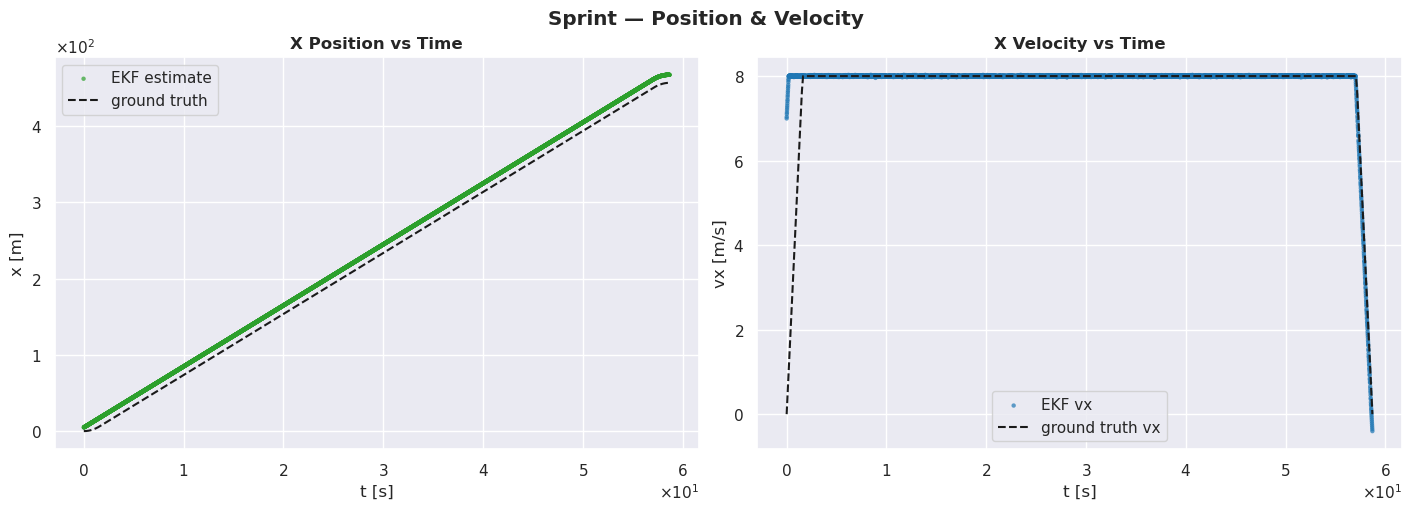

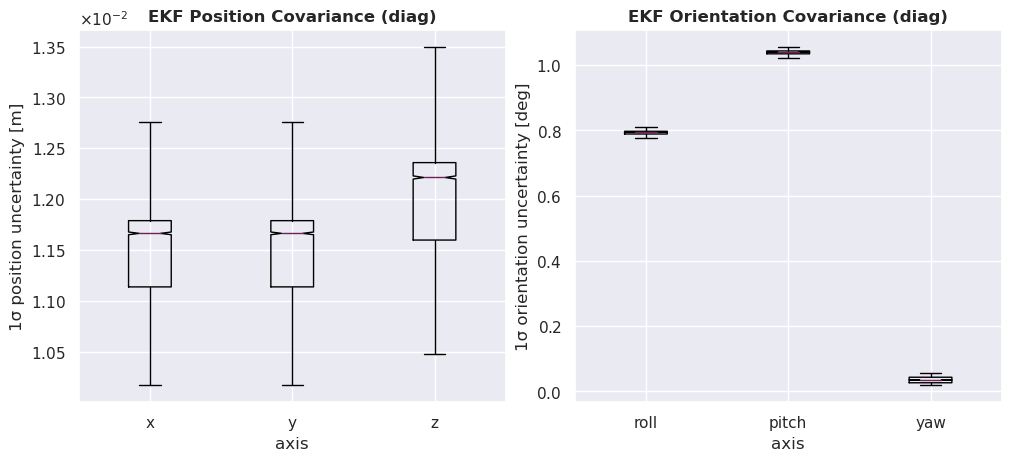

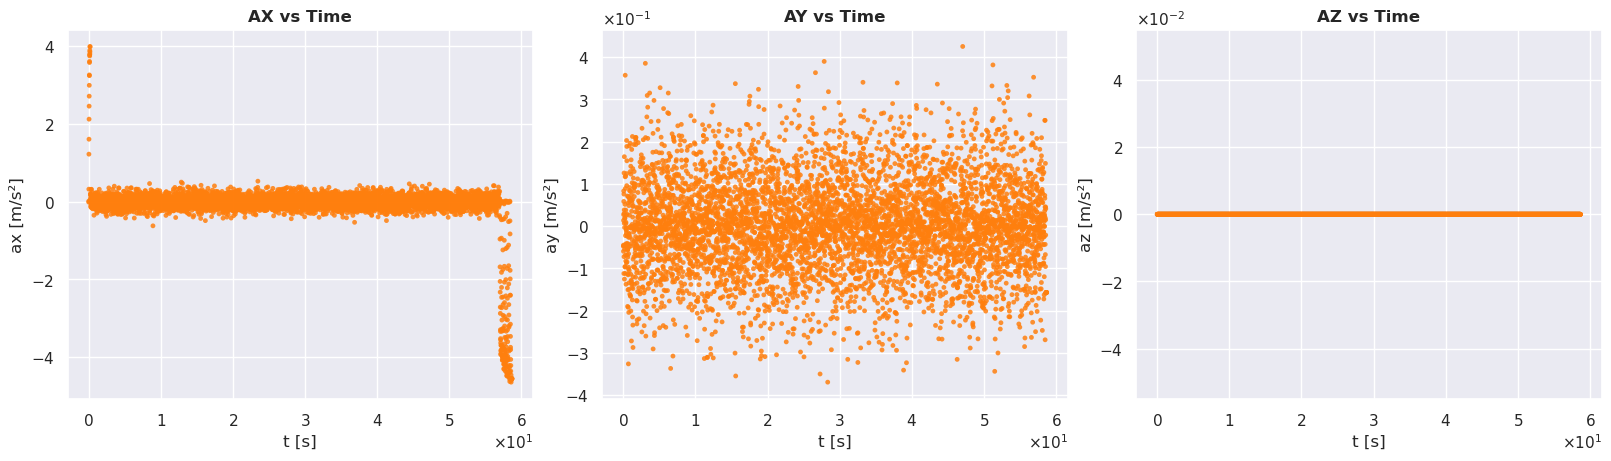

In [6]:
# Sprint ground-truth: analytical sprint_x(t) and sprint_vx(t)
SPRINT_A    = 5.0   # m/s²
SPRINT_VMAX = 8.0   # m/s
duration_sprint = find_t_rel(sprint_ekf).max()

def sprint_vx_gt(t, dur):
    t_ramp = SPRINT_VMAX / SPRINT_A
    vx = np.where(t < t_ramp, SPRINT_A * t,
         np.where(t < dur - t_ramp, SPRINT_VMAX,
                  np.maximum(0.0, SPRINT_VMAX - SPRINT_A * (t - (dur - t_ramp)))))
    return vx

def sprint_x_gt(t, dur):
    t_ramp = SPRINT_VMAX / SPRINT_A
    x_ramp = 0.5 * SPRINT_A * t_ramp**2
    t3 = np.maximum(0.0, t - (dur - t_ramp))
    x = np.where(t < t_ramp, 0.5 * SPRINT_A * t**2,
        np.where(t < dur - t_ramp, x_ramp + SPRINT_VMAX * (t - t_ramp),
                 x_ramp + SPRINT_VMAX * (dur - 2 * t_ramp) + SPRINT_VMAX * t3 - 0.5 * SPRINT_A * t3**2))
    return x

t_rel = find_t_rel(sprint_ekf)
t_gt  = np.linspace(0, duration_sprint, 500)

sns.set_theme(style="darkgrid", context="notebook")
fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
fig.suptitle("Sprint — Position & Velocity", weight="bold")

axes[0].scatter(t_rel, sprint_ekf["x"], s=10, color="tab:green", alpha=0.7, label="EKF estimate", edgecolors="none")
axes[0].plot(t_gt, sprint_x_gt(t_gt, duration_sprint), "k--", label="ground truth")
axes[0].set_xlabel("t [s]")
axes[0].set_ylabel("x [m]")
axes[0].set_title("X Position vs Time", weight="bold")
axes[0].legend()

axes[1].scatter(t_rel, sprint_ekf["vx"], s=10, color="tab:blue", alpha=0.7, label="EKF vx", edgecolors="none")
axes[1].plot(t_gt, sprint_vx_gt(t_gt, duration_sprint), "k--", label="ground truth vx")
axes[1].set_xlabel("t [s]")
axes[1].set_ylabel("vx [m/s]")
axes[1].set_title("X Velocity vs Time", weight="bold")
axes[1].legend()

plt.show()

plot_state_covariance_boxplot(sprint_ekf)
plot_time_series_scatter_accel(sprint_accel)

In [7]:
t_rel_sprint = find_t_rel(sprint_ekf).to_numpy()
x_gt_sprint  = sprint_x_gt(t_rel_sprint, duration_sprint)
x_err = sprint_ekf["x"].to_numpy() - x_gt_sprint

vx_gt_sprint = sprint_vx_gt(t_rel_sprint, duration_sprint)
vx_err = sprint_ekf["vx"].to_numpy() - vx_gt_sprint

print(f"Position x error — mean: {x_err.mean():.4f} m, std: {x_err.std():.4f} m, RMS: {np.sqrt((x_err**2).mean()):.4f} m")
print(f"Velocity vx error — mean: {vx_err.mean():.4f} m/s, std: {vx_err.std():.4f} m/s, RMS: {np.sqrt((vx_err**2).mean()):.4f} m/s")
print(f"y std: {sprint_ekf['y'].std():.4f} m")
print(f"z std: {sprint_ekf['z'].std():.4f} m")

Position x error — mean: 11.1376 m, std: 0.4751 m, RMS: 11.1477 m
Velocity vx error — mean: 0.0954 m/s, std: 0.7465 m/s, RMS: 0.7526 m/s
y std: 0.0085 m
z std: 0.0087 m


---
## Scenario 2 — Slalom

Forward flight at 3 m/s with sinusoidal yaw oscillation (±109°, 8 s period).
World-frame position traces a slalom path in the XY plane.

VIO orientation is disabled; the sparse 5 Hz vision corrections are the **sole
absolute heading source**. This is the hardest orientation scenario:
large heading swings combined with long dead-reckoning windows.

**Key diagnostic**: 2D top-view trajectory (x vs y) should show a coherent
sinusoidal slalom path. Yaw time series should track the oscillation.

In [8]:
slalom_ekf = pd.read_csv(TESTS_DIR / "slalom_hard_ekf" / "scenario_data.csv")
slalom_ekf = add_rpy_from_quat(slalom_ekf)
slalom_accel = pd.read_csv(TESTS_DIR / "slalom_hard_ekf" / "accel_data.csv")

print(f"EKF samples: {len(slalom_ekf)},  duration: {find_t_rel(slalom_ekf).max():.1f} s")
print(f"Accel samples: {len(slalom_accel)}")

EKF samples: 5924,  duration: 59.2 s
Accel samples: 5924


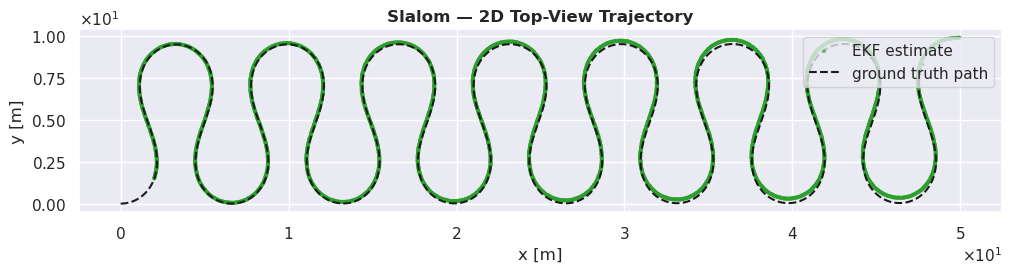

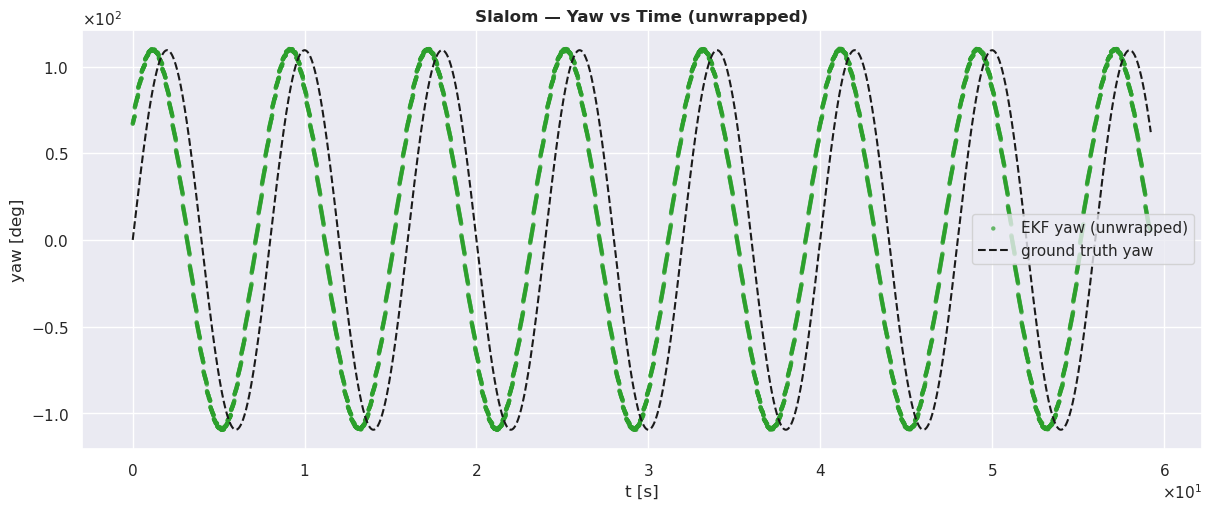

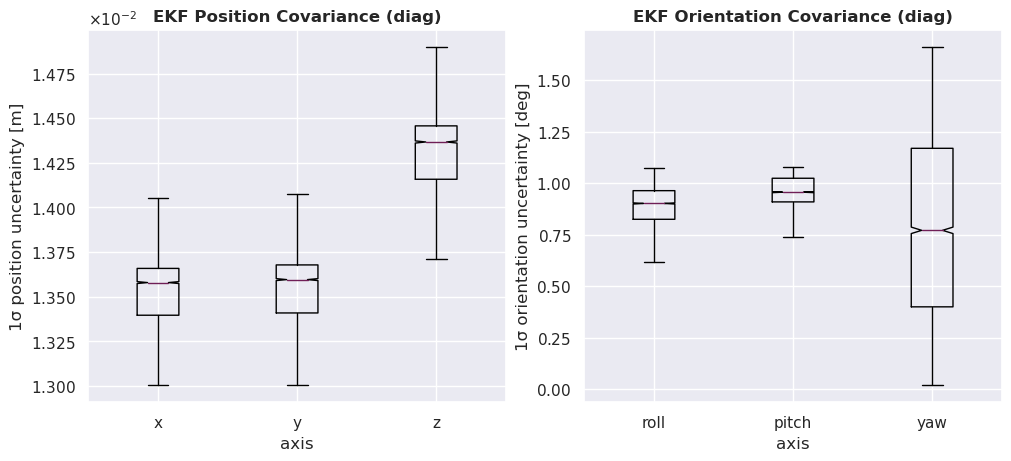

In [9]:
# Slalom ground truth: Euler-integrated world path
SLALOM_VFW   = 3.0
SLALOM_WZMAX = 1.5
SLALOM_OMEGA = 2.0 * np.pi / 8.0

duration_slalom = find_t_rel(slalom_ekf).max()
dt_gt = 0.001
t_gt_s = np.arange(0, duration_slalom, dt_gt)
x_gt_s, y_gt_s, yaw_gt_s = 0.0, 0.0, 0.0
x_list, y_list, yaw_list = [], [], []
for t_i in t_gt_s:
    wz = SLALOM_WZMAX * np.cos(SLALOM_OMEGA * t_i)
    yaw_gt_s += wz * dt_gt
    x_gt_s   += SLALOM_VFW * np.cos(yaw_gt_s) * dt_gt
    y_gt_s   += SLALOM_VFW * np.sin(yaw_gt_s) * dt_gt
    x_list.append(x_gt_s)
    y_list.append(y_gt_s)
    yaw_list.append(yaw_gt_s)
x_gt_arr   = np.array(x_list)
y_gt_arr   = np.array(y_list)
yaw_gt_arr = np.rad2deg(np.array(yaw_list))

sns.set_theme(style="darkgrid", context="notebook")

# 2D trajectory (top view — key diagnostic for slalom)
fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
ax.scatter(slalom_ekf["x"], slalom_ekf["y"], s=8, color="tab:green", alpha=0.6,
           label="EKF estimate", edgecolors="none")
ax.plot(x_gt_arr, y_gt_arr, "k--", lw=1.5, label="ground truth path")
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
ax.set_title("Slalom — 2D Top-View Trajectory", weight="bold")
ax.set_aspect("equal", "box")
ax.legend()
plt.show()

# Yaw time series (unwrapped)
t_rel_slalom = find_t_rel(slalom_ekf)
yaw_unwrapped = np.rad2deg(np.unwrap(np.deg2rad(slalom_ekf["yaw_deg"].to_numpy())))

fig, ax = plt.subplots(figsize=(12, 5), constrained_layout=True)
ax.scatter(t_rel_slalom, yaw_unwrapped, s=10, color="tab:green", alpha=0.7,
           label="EKF yaw (unwrapped)", edgecolors="none")
ax.plot(t_gt_s, yaw_gt_arr, "k--", lw=1.5, label="ground truth yaw")
ax.set_xlabel("t [s]")
ax.set_ylabel("yaw [deg]")
ax.set_title("Slalom — Yaw vs Time (unwrapped)", weight="bold")
ax.legend()
plt.show()

plot_state_covariance_boxplot(slalom_ekf)

In [10]:
print(f"x std: {slalom_ekf['x'].std():.4f} m")
print(f"y std: {slalom_ekf['y'].std():.4f} m")
print(f"yaw std (unwrapped): {yaw_unwrapped.std():.2f} deg")

mean_pos_std = (slalom_ekf["x"].std() + slalom_ekf["y"].std() + slalom_ekf["z"].std()) / 3.0
print(f"Mean position std: {mean_pos_std:.4f} m")

x std: 14.1659 m
y std: 3.1281 m
yaw std (unwrapped): 77.66 deg
Mean position std: 5.7675 m


---
## Scenario 3 — Pitch Dive

Forward flight at 4 m/s with oscillating pitch (±40°, 6 s period).
This drives alternating climbs and dives, coupling the x and z axes.

VIO orientation is disabled; the EKF must reconstruct pitch from the angular
rate signal (angular.y) and the gravity-coupling term in the drone physics model.
Pitch up to ±40° stresses the legacy Euler EKF (near gimbal lock) while
remaining nominal for the quaternion EKF.

**Key diagnostic**: x vs z side-view scatter should show the dive/climb arc.
Pitch time series should match ±40° oscillation.

In [11]:
pitch_dive_ekf = pd.read_csv(TESTS_DIR / "pitch_dive_hard_ekf" / "scenario_data.csv")
pitch_dive_ekf = add_rpy_from_quat(pitch_dive_ekf)
pitch_dive_accel = pd.read_csv(TESTS_DIR / "pitch_dive_hard_ekf" / "accel_data.csv")

print(f"EKF samples: {len(pitch_dive_ekf)},  duration: {find_t_rel(pitch_dive_ekf).max():.1f} s")
print(f"Accel samples: {len(pitch_dive_accel)}")

EKF samples: 5923,  duration: 59.2 s
Accel samples: 5923


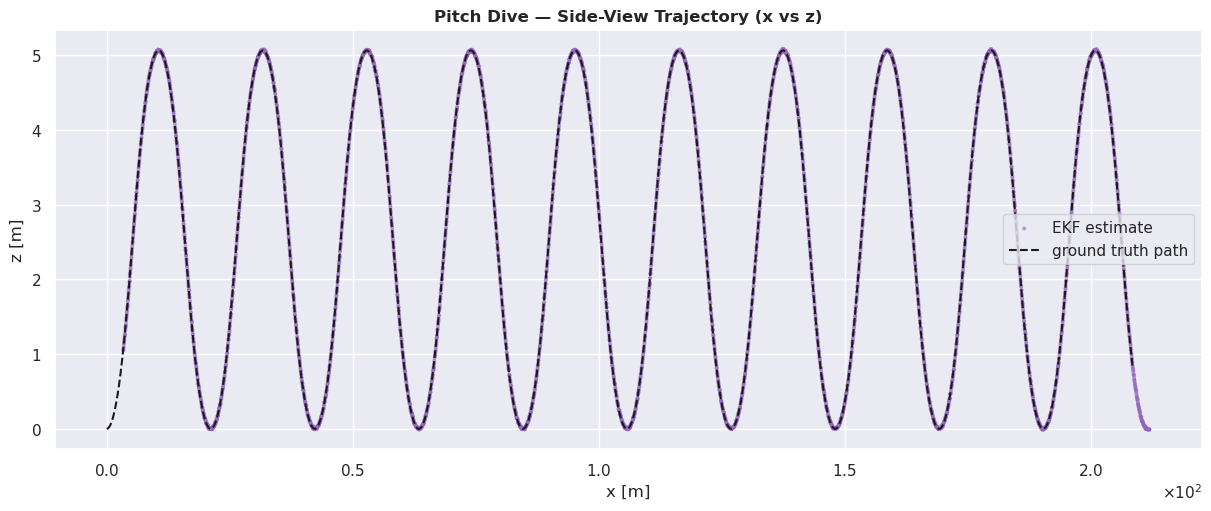

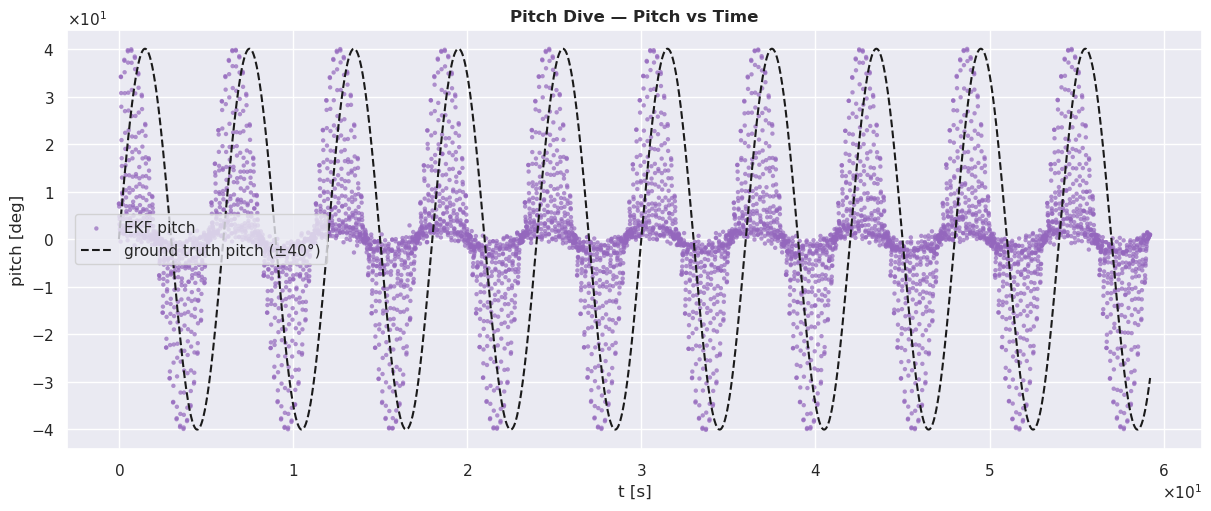

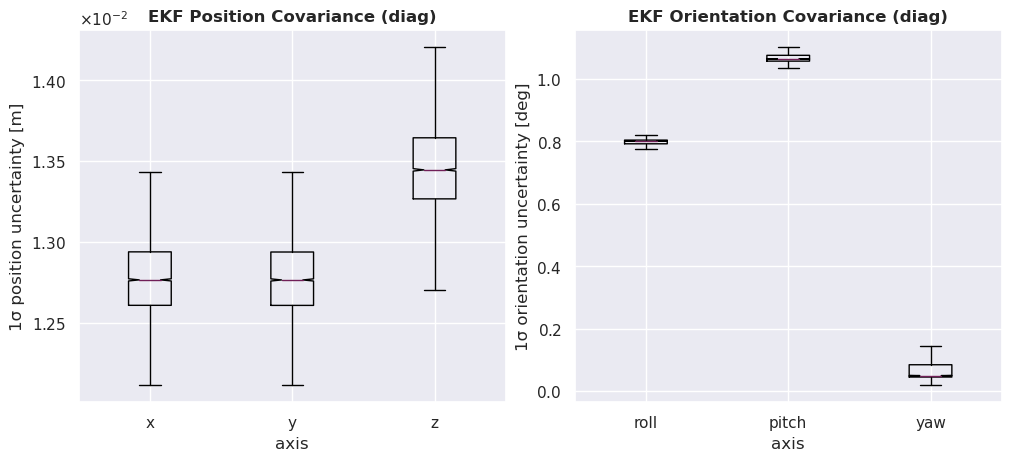

In [12]:
PITCH_VFW   = 4.0
PITCH_AMP   = 0.7
PITCH_OMEGA_PY = 2.0 * np.pi / 6.0

duration_pitch = find_t_rel(pitch_dive_ekf).max()
dt_gt_p = 0.001
t_gt_p = np.arange(0, duration_pitch, dt_gt_p)
x_gt_p, z_gt_p = 0.0, 0.0
x_p_list, z_p_list = [], []
for t_i in t_gt_p:
    pitch_i = PITCH_AMP * np.sin(PITCH_OMEGA_PY * t_i)
    x_gt_p += PITCH_VFW * np.cos(pitch_i) * dt_gt_p
    z_gt_p += PITCH_VFW * np.sin(pitch_i) * dt_gt_p
    x_p_list.append(x_gt_p)
    z_p_list.append(z_gt_p)

x_gt_p_arr = np.array(x_p_list)
z_gt_p_arr = np.array(z_p_list)
pitch_gt_arr = np.rad2deg(PITCH_AMP * np.sin(PITCH_OMEGA_PY * t_gt_p))

sns.set_theme(style="darkgrid", context="notebook")

# Side-view trajectory (x vs z)
fig, ax = plt.subplots(figsize=(12, 5), constrained_layout=True)
ax.scatter(pitch_dive_ekf["x"], pitch_dive_ekf["z"], s=8, color="tab:purple", alpha=0.6,
           label="EKF estimate", edgecolors="none")
ax.plot(x_gt_p_arr, z_gt_p_arr, "k--", lw=1.5, label="ground truth path")
ax.set_xlabel("x [m]")
ax.set_ylabel("z [m]")
ax.set_title("Pitch Dive — Side-View Trajectory (x vs z)", weight="bold")
ax.legend()
plt.show()

# Pitch time series with ground truth overlay
t_rel_pitch = find_t_rel(pitch_dive_ekf)

fig, ax = plt.subplots(figsize=(12, 5), constrained_layout=True)
ax.scatter(t_rel_pitch, pitch_dive_ekf["pitch_deg"], s=10, color="tab:purple", alpha=0.7,
           label="EKF pitch", edgecolors="none")
ax.plot(t_gt_p, pitch_gt_arr, "k--", lw=1.5, label=f"ground truth pitch (\u00b1{np.rad2deg(PITCH_AMP):.0f}\u00b0)")
ax.set_xlabel("t [s]")
ax.set_ylabel("pitch [deg]")
ax.set_title("Pitch Dive — Pitch vs Time", weight="bold")
ax.legend()
plt.show()

plot_state_covariance_boxplot(pitch_dive_ekf)

In [13]:
t_rel_pitch_np = find_t_rel(pitch_dive_ekf).to_numpy()
pitch_gt_vals  = np.rad2deg(PITCH_AMP * np.sin(PITCH_OMEGA_PY * t_rel_pitch_np))
pitch_err = pitch_dive_ekf["pitch_deg"].to_numpy() - pitch_gt_vals

print(f"Pitch error — mean: {pitch_err.mean():.3f} deg, std: {pitch_err.std():.3f} deg, RMS: {np.sqrt((pitch_err**2).mean()):.3f} deg")
print(f"x std: {pitch_dive_ekf['x'].std():.4f} m")
print(f"z std: {pitch_dive_ekf['z'].std():.4f} m")

Pitch error — mean: -0.290 deg, std: 25.231 deg, RMS: 25.232 deg
x std: 60.2709 m
z std: 1.7720 m


---
## Scenario 4 — Dropout

Constant turning flight (ω_z = 0.5 rad/s, v_x = 2 m/s) identical to the
easy *turn* scenario, but VIO is silenced for 2.5 s every 7 s window,
simulating visual-tracking loss during fast gate passages.

During a dropout the EKF receives **no VIO corrections** and must dead-reckon
orientation exclusively from the angular-rate decay model and the sparse
5 Hz vision corrections. This directly tests the quality of the quaternion
predict step.

**Key diagnostic**: Yaw time series should track ω·t through the shaded dropout
windows without significant drift.

In [14]:
dropout_ekf = pd.read_csv(TESTS_DIR / "dropout_hard_ekf" / "scenario_data.csv")
dropout_ekf = add_rpy_from_quat(dropout_ekf)
dropout_accel = pd.read_csv(TESTS_DIR / "dropout_hard_ekf" / "accel_data.csv")

print(f"EKF samples: {len(dropout_ekf)},  duration: {find_t_rel(dropout_ekf).max():.1f} s")
print(f"Accel samples: {len(dropout_accel)}")

EKF samples: 5910,  duration: 59.1 s
Accel samples: 5912


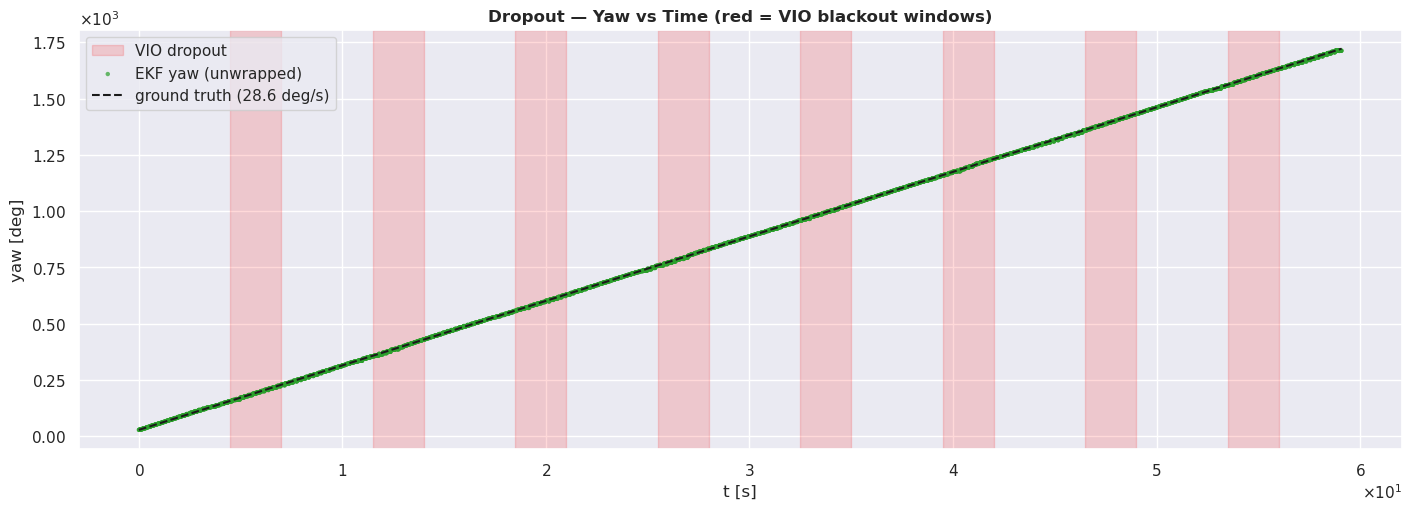

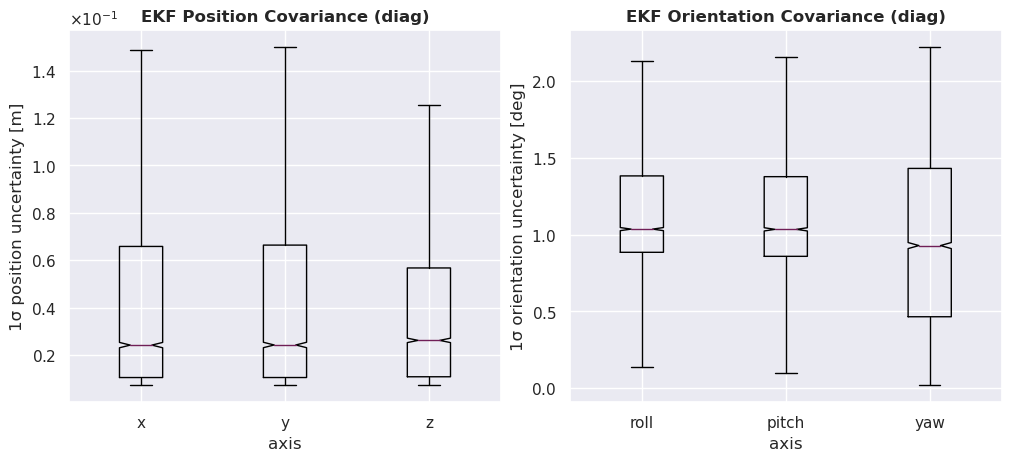

In [15]:
DROPOUT_OMEGA_RAD = 0.5   # rad/s
DROP_PERIOD_S     = 7.0   # s
DROP_DUR_S        = 2.5   # s
duration_dropout  = find_t_rel(dropout_ekf).max()

t_rel_dropout = find_t_rel(dropout_ekf)
yaw_gt_dropout = np.rad2deg(DROPOUT_OMEGA_RAD * t_rel_dropout.to_numpy())
yaw_unwrapped_d = np.rad2deg(np.unwrap(np.deg2rad(dropout_ekf["yaw_deg"].to_numpy())))
yaw_0_d = yaw_unwrapped_d[0]

sns.set_theme(style="darkgrid", context="notebook")
fig, ax = plt.subplots(figsize=(14, 5), constrained_layout=True)

# Shade dropout windows
k = 0
while True:
    t_start = DROP_PERIOD_S * k + DROP_PERIOD_S - DROP_DUR_S
    t_end   = DROP_PERIOD_S * (k + 1)
    if t_start > duration_dropout:
        break
    ax.axvspan(t_start, min(t_end, duration_dropout), alpha=0.15, color="red",
               label="VIO dropout" if k == 0 else "_nolegend_")
    k += 1

ax.scatter(t_rel_dropout, yaw_unwrapped_d, s=10, color="tab:green", alpha=0.7,
           label="EKF yaw (unwrapped)", edgecolors="none")
ax.plot(t_rel_dropout, yaw_0_d + np.rad2deg(DROPOUT_OMEGA_RAD) * t_rel_dropout.to_numpy(),
        "k--", lw=1.5, label=f"ground truth ({np.rad2deg(DROPOUT_OMEGA_RAD):.1f} deg/s)")
ax.set_xlabel("t [s]")
ax.set_ylabel("yaw [deg]")
ax.set_title("Dropout — Yaw vs Time (red = VIO blackout windows)", weight="bold")
ax.legend()
plt.show()

plot_state_covariance_boxplot(dropout_ekf)

In [16]:
yaw_err_d = yaw_unwrapped_d - (yaw_0_d + np.rad2deg(DROPOUT_OMEGA_RAD) * t_rel_dropout.to_numpy())
print(f"Yaw tracking error — mean: {yaw_err_d.mean():.3f} deg, std: {yaw_err_d.std():.3f} deg, RMS: {np.sqrt((yaw_err_d**2).mean()):.3f} deg")
print(f"x std: {dropout_ekf['x'].std():.4f} m")
print(f"y std: {dropout_ekf['y'].std():.4f} m")

Yaw tracking error — mean: -1.241 deg, std: 1.946 deg, RMS: 2.308 deg
x std: 34.1242 m
y std: 0.0313 m
